## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [12]:
import pickle

with open('/content/A05-pca/data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):**

**Date:** [To be provided]

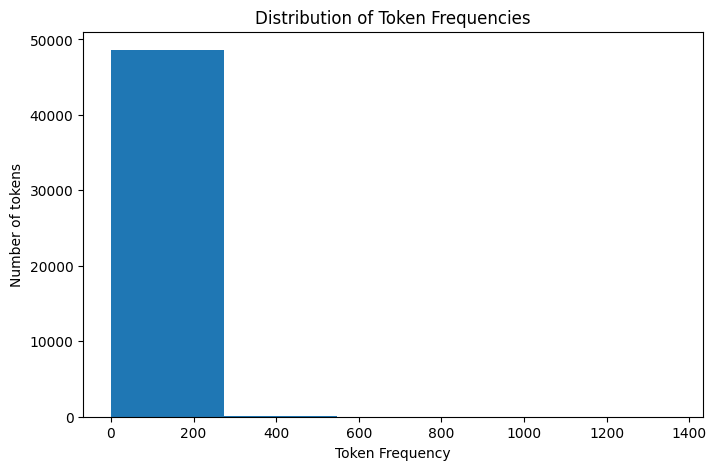

The distribution is heavily right-skewed. A small number of tokens appear very frequently and most token occur only a few times. This creates a large peak on the left with an extending tail to the right


In [19]:
# Your Phase 1 solution to the problem goes here.
#Q1
import matplotlib.pyplot as plt

frequencies = [count for word, count in token_freq]

plt.figure(figsize=(8, 5))
plt.hist(frequencies, bins=5)
plt.xlabel("Token Frequency")
plt.ylabel("Number of tokens")
plt.title("Distribution of Token Frequencies")
plt.show()

print("The distribution is heavily right-skewed. A small number of tokens appear very frequently and most token occur only a few times. This creates a large peak on the left with an extending tail to the right")



In [20]:
#Q2

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df = pd.read_parquet("/content/A05-pca/data/Phishing_clean.parquet")
X = df.drop(columns=["Email Type"])
y = df["Email Type"]

Xtrain, Xtest, ytrain, ytest = train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)
model=LinearRegression()
model.fit(Xtrain, ytrain)

print("Training R2:", model.score(Xtrain, ytrain))
print("Test R2:", model.score(Xtest, ytest))

coeffs = pd.Series(model.coef_, index=X.columns)
print("\nLargest coeffcients: ")
print(coeffs.reindex(coeffs.abs().sort_values(ascending=False).index).head(10))

print("The training R2 is 0.7713 while the test R2 is 0.6424. The lower test score suggest some overfitting. The tokens with the largest absolute co-efficients include 'background-image', 'localized', thermal, etc,. Most of these have positive coefficients which means they increase the predicted likelihood of phishing, while. backgroun-image has a negative coefficient")

Training R2: 0.7713488230210973
Test R2: 0.6424054770149773

Largest coeffcients: 
background-image:   -1.016799
localized            0.839522
thermal              0.699684
#000000;             0.615728
#331f30;             0.615728
form.                0.593718
aging                0.586465
erectile             0.538953
girlfriend           0.527557
xanaax               0.516449
dtype: float64
The training R2 is 0.7713 while the test R2 is 0.6424. The lower test score suggest some overfitting. The tokens with the largest absolute co-efficients include 'background-image', 'localized', thermal, etc,. Most of these have positive coefficients which means they increase the predicted likelihood of phishing, while. backgroun-image has a negative coefficient


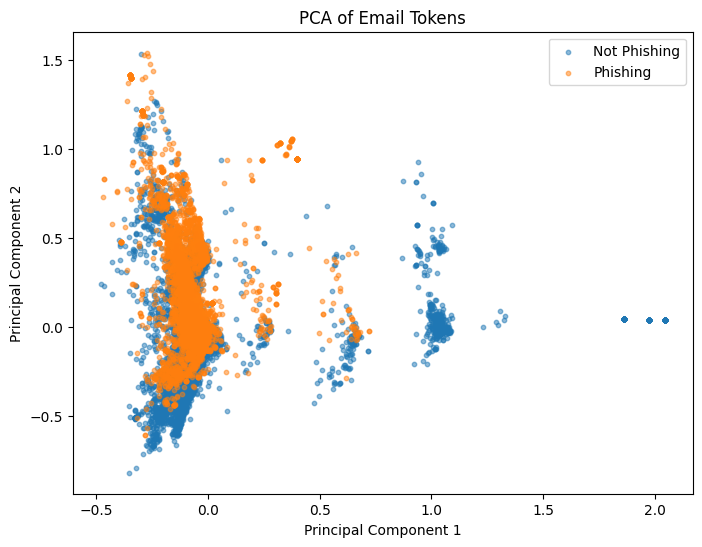

The two groups overlap especially on the left side of the plot. However, there are some clusters on the right that contain mostly non-phishing emails. This suggests that the first 2 principal components capture some differences between the email types, but they don't clearly separate phishing from non-phishing emails. 


In [22]:
#Q3

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
plt.figure(figsize=(8,6))
plt.scatter(X_pca[y==0,0],X_pca[y==0,1], label="Not Phishing", alpha=0.5, s=10)
plt.scatter(X_pca[y==1,0],X_pca[y==1,1], label="Phishing", alpha=0.5, s=10)
plt.xlabel('Principal Component 1')
plt.ylabel("Principal Component 2")
plt.title("PCA of Email Tokens")
plt.legend()
plt.show()

print("The two groups overlap especially on the left side of the plot. However, there are some clusters on the right that contain mostly non-phishing emails. This suggests that the first 2 principal components capture some differences between the email types, but they don't clearly separate phishing from non-phishing emails. ")

In [25]:
#Q4
pca=PCA(n_components=2610)
Xtrain_pca = pca.fit_transform(Xtrain)
Xtest_pca = pca.transform(Xtest)

model_pca = LinearRegression()
model_pca.fit(Xtrain_pca, ytrain)

print("PCA Training R2:", model_pca.score(Xtrain_pca, ytrain))
print("PCA Test R2:", model_pca.score(Xtest_pca, ytest))

print("Original Training R2:", model.score(Xtrain, ytrain))
print("Original Test R2:", model.score(Xtest, ytest))

print("The results above show that both mode;s perform similarly, but PCA gives a slightly higher test R2 while using fewwer features")

PCA Training R2: 0.7707405054535216
PCA Test R2: 0.6449635103096862
Original Training R2: 0.7713488230210973
Original Test R2: 0.6424054770149773
The results above show that both mode;s perform similarly, but PCA gives a slightly higher test R2 while using fewwer features


In [26]:
#Q5

print("PCA reduces the number of features by combining correlated variables into principal components. This makes high-dimensional regression easier to handle and it can also help reduce overfitting while preserving most of the variation in the data")

PCA reduces the number of features by combining correlated variables into principal components. This makes high-dimensional regression easier to handle and it can also help reduce overfitting while preserving most of the variation in the data


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 7af50def23fede245c1f3b4a6f14806e12196484
- **AI tool and model used:** ChatGPT

### *Prompts used

1. Audit and revise my Phase 1 solution. Check if my code correctly answers each question and give me a numbered list of specific changes.
2. Only mention errors related to the code

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. . Q1 — Increase the histogram bins. Change bins=5 to bins=50 to show more detail in the token frequency distribution. The current five-bin histogram compresses most tokens into one large bar.

2. Q1 — Display the most frequent tokens. Add print(token_count.most_common(10)) to identify the ten most common tokens, as suggested by the assignment instructions.

3. Q2 — Clarify the coefficient interpretation. The regression is an ordinary linear regression, so its predictions are not necessarily valid probabilities. Instead of saying positive coefficients increase the "likelihood of phishing," explain that they increase the predicted value of Email Type, holding other features constant.

4. Q2 — Use the exact token names. The strongest coefficients include background-image:, localized, and thermal. Preserve the punctuation in token names and mention that some important features are HTML or formatting tokens rather than ordinary words.

5. Q3 — Add explained variance information. Keep the scatter plot, which correctly shows substantial overlap between phishing and non-phishing emails. Optionally print pca.explained_variance_ratio_ to report how much variation the first two principal components explain.

6. Q4 — Use separate PCA variable names. Instead of reusing pca for both questions, use pca_2 for Q3 and pca_2610 for Q4. This improves readability and prevents accidentally using the wrong fitted PCA object.

7. Q4 — Make the model comparison more precise. The original test \(R^2\) is 0.6424, while the PCA test \(R^2\) is 0.6450. This is an improvement of approximately 0.0026, which is very small. Explain that PCA produces comparable performance rather than claiming a substantial improvement.

8. Q5 — Clarify the advantage of PCA. PCA produces uncorrelated components and can reduce dimensionality while retaining important variation. However, using 2,610 components instead of 2,711 original features is only a modest reduction. PCA also does not guarantee less overfitting or better predictions.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | reject | The bins were first set 50 but the distribution was heavily skewed so I reduced the bin number|
| 2 | Accept | The assignment asks to examine the most common tokens and printing the top 10 gives more information  |
| 3 | Accept | The explanation should refer to predicted email type rather than phishing probability |
| 4 | Accept | Keeping the original token names, including the punctuation makes makes the interpretation more accurate |
| 5 | Reject | Not required per assignment's instruction |
| 6 | Reject | Reusing the pca doesnt affect the results because the Q4 firs a new PCA model |
| 7 | Accept | The PCA test R2 only improves a vry little amount so the explanation should emphasize that difference |
| 8 | Reject | Not needed |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

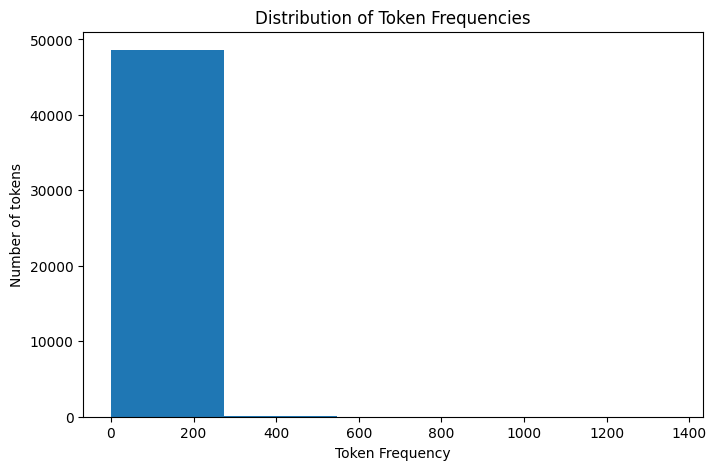

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]
The distribution is heavily right-skewed. A small number of tokens appear very frequently and most token occur only a few times. This creates a large peak on the left with an extending tail to the right
Training R2: 0.7713488230210973
Test R2: 0.6424054770149773

Largest coeffcients: 
background-image:   -1.016799
localized            0.839522
thermal              0.699684
#000000;             0.615728
#331f30;             0.615728
form.                0.593718
aging                0.586465
erectile             0.538953
girlfriend           0.527557
xanaax               0.516449
dtype: float64
The training R2 is 0.7713 while the test R2 is 0.6424. The lower test score suggest some overfitting. The tokens with the largest absolute co-efficients include 'background-image:', 'localized', 'thermal', etc. Most of these have positive c

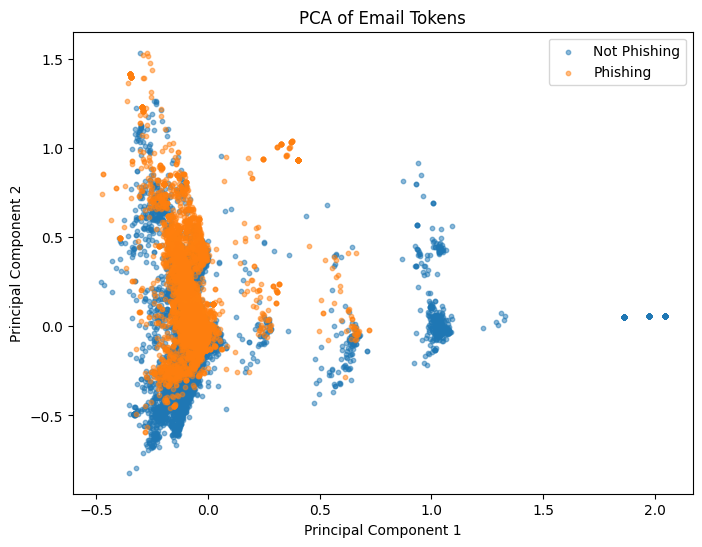

The two groups overlap especially on the left side of the plot. However, there are some clusters on the right that contain mostly non-phishing emails. This suggests that the first 2 principal components capture some differences between the email types, but they don't clearly separate phishing from non-phishing emails. 
PCA Training R2: 0.7707405054535216
PCA Test R2: 0.6449635103096862
Original Training R2: 0.7713488230210973
Original Test R2: 0.6424054770149773
The results above show that both models perform similarly. The PCA test R2 is 0.6450 compared to 0.6424 for the original regression. This is a very small improvement of about 0.0026, so PCA provides comparable performance while using fewer features
PCA reduces the number of features by combining correlated variables into principal components. This makes high-dimensional regression easier to handle and it can also help reduce overfitting while preserving most of the variation in the data


In [27]:
# Your Phase 2 solution to the problem goes here.


# Your Phase 2 solution to the problem goes here.

#Q1
import matplotlib.pyplot as plt

frequencies = [count for word, count in token_freq]

plt.figure(figsize=(8, 5))
plt.hist(frequencies, bins=5)
plt.xlabel("Token Frequency")
plt.ylabel("Number of tokens")
plt.title("Distribution of Token Frequencies")
plt.show()

print(token_count.most_common(10))

print("The distribution is heavily right-skewed. A small number of tokens appear very frequently and most token occur only a few times. This creates a large peak on the left with an extending tail to the right")


#Q2

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df = pd.read_parquet("/content/A05-pca/data/Phishing_clean.parquet")
X = df.drop(columns=["Email Type"])
y = df["Email Type"]

Xtrain, Xtest, ytrain, ytest = train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)
model=LinearRegression()
model.fit(Xtrain, ytrain)

print("Training R2:", model.score(Xtrain, ytrain))
print("Test R2:", model.score(Xtest, ytest))

coeffs = pd.Series(model.coef_, index=X.columns)
print("\nLargest coeffcients: ")
print(coeffs.reindex(coeffs.abs().sort_values(ascending=False).index).head(10))

print("The training R2 is 0.7713 while the test R2 is 0.6424. The lower test score suggest some overfitting. The tokens with the largest absolute co-efficients include 'background-image:', 'localized', 'thermal', etc. Most of these have positive coefficients which means they increase the predicted value of Email Type, while 'background-image:' has a negative coefficient")


#Q3

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
plt.figure(figsize=(8,6))
plt.scatter(X_pca[y==0,0],X_pca[y==0,1], label="Not Phishing", alpha=0.5, s=10)
plt.scatter(X_pca[y==1,0],X_pca[y==1,1], label="Phishing", alpha=0.5, s=10)
plt.xlabel('Principal Component 1')
plt.ylabel("Principal Component 2")
plt.title("PCA of Email Tokens")
plt.legend()
plt.show()

print("The two groups overlap especially on the left side of the plot. However, there are some clusters on the right that contain mostly non-phishing emails. This suggests that the first 2 principal components capture some differences between the email types, but they don't clearly separate phishing from non-phishing emails. ")


#Q4
pca=PCA(n_components=2610)
Xtrain_pca = pca.fit_transform(Xtrain)
Xtest_pca = pca.transform(Xtest)

model_pca = LinearRegression()
model_pca.fit(Xtrain_pca, ytrain)

print("PCA Training R2:", model_pca.score(Xtrain_pca, ytrain))
print("PCA Test R2:", model_pca.score(Xtest_pca, ytest))

print("Original Training R2:", model.score(Xtrain, ytrain))
print("Original Test R2:", model.score(Xtest, ytest))

print("The results above show that both models perform similarly. The PCA test R2 is 0.6450 compared to 0.6424 for the original regression. This is a very small improvement of about 0.0026, so PCA provides comparable performance while using fewer features")


#Q5

print("PCA reduces the number of features by combining correlated variables into principal components. This makes high-dimensional regression easier to handle and it can also help reduce overfitting while preserving most of the variation in the data")



### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]


I accepted the suggestions to display the 10 most common tokens, clarify the interpretations of regression coefficients , keep the original token names, and explain the small difference in R2 between the mdoels. However I rejected some suggestions as they were unnecessary or didn't improve my solution. For example, using more histogram bins made the heavily skewed distribution harder to interpret and changing PCA variables would not affect the results. One limitation of the AI review was that it suggested optional changes rather than focusing only on actual errors. I verified my final solution by checking the plots, comparing the regression scores and also making sure that the explanations matched the outputs. Both models performed similarly. One remaining concern is that the regression shows some overfitting since the training R2 is higher than the test R2